# 🌋 PyTorch ile Sismik Aktivite Sınıflandırması: Doğrusal (Linear) vs Doğrusal Olmayan (ReLU)

Bu notebook, **Atıl Samancıoğlu Derin Öğrenme Eğitimi Modül 08 Ödevi** kapsamında hazırlanmıştır.

### 🎯 Ödevin Temel Amacı:
1. **Verinin Doğasını Keşfetmek:** Doğrusal olarak ayrılamayan (non-linear, dairesel/kıvrımlı) bir veri setini incelemek.
2. **Doğrusal Modelin Çöküşünü Görmek (Baseline):** Aktivasyon fonksiyonu olmadan kurulan çok katmanlı modelin neden düz bir çizgiden öteye geçemediğini ve test doğruluğunun neden **%43.75** gibi şans eseri (yazı tura) seviyesinde kaldığını gözlemlemek.
3. **Aktivasyon Fonksiyonunun (ReLU) Gücü:** Araya tek bir satırla `nn.ReLU()` ekleyerek sinir ağının uzayı bükme yeteneğini açığa çıkarmak ve doğruluğu **%100'e** ulaştırmak.
4. **Karar Sınırlarını (Decision Boundary) Görselleştirmek:** İki modelin karar sınırlarını yan yana çizdirip aradaki farkı somut olarak görmek.

## 1. Gerekli Kütüphanelerin Yüklenmesi

In [1]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Donanım kontrolü (Apple Silicon MPS / NVIDIA CUDA / CPU)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"PyTorch Versiyonu: {torch.__version__} | Aktif Donanım: {device}")

PyTorch Versiyonu: 2.14.0 | Aktif Donanım: mps


## 2. Sismik Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

Veri seti sensörlerden alınan 2 temel özellik ve deprem olup olmadığını belirten hedef değişkenden oluşur:
- **`underground_wave_energy`**: Yeraltı sismik dalga enerjisi.
- **`vibration_axis_variation`**: Titreşim eksenindeki sapma miktarı.
- **`seismic_event_detected`**: Hedef değişken $\rightarrow$ `0 = Deprem Yok`, `1 = Deprem Var`.

In [2]:
# CSV veri setini oku
df = pd.read_csv("08-seismic_activity_svm.csv")

# İlk 5 satırı incele
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [3]:
# Veri tipleri ve eksik değer kontrolü
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [4]:
# İstatistiksel özet
df.describe()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
count,400.000000,4.000000e+02,400.000000
mean,0.000000,8.881784e-18,0.500000
std,7.719350,1.751650e+00,0.500626
min,-9.999954,-3.000000e+00,0.000000
25%,-6.134779,-1.500000e+00,0.000000
50%,0.000000,0.000000e+00,0.500000
75%,6.134779,1.500000e+00,1.000000
max,9.999954,3.000000e+00,1.000000


In [5]:
# Sınıf dağılımını kontrol et (0 ve 1 dengeli mi?)
print("Sınıf Dağılımı:\n", df["seismic_event_detected"].value_counts())

Sınıf Dağılımı:
 seismic_event_detected
0    200
1    200
Name: count, dtype: int64


### 📊 Verinin Dağılımını Görselleştirme (Scatter Plot)
Veriyi iki boyutlu uzayda çizdirerek sınıfların nasıl konumlandığını inceliyoruz.

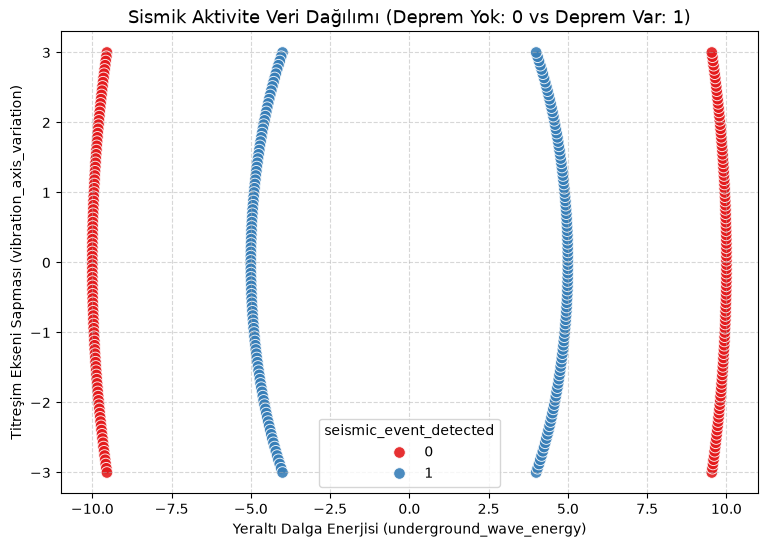

In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['underground_wave_energy'],
    y=df['vibration_axis_variation'],
    hue=df['seismic_event_detected'],
    palette="Set1",
    s=70,
    alpha=0.9
)
plt.title("Sismik Aktivite Veri Dağılımı (Deprem Yok: 0 vs Deprem Var: 1)", fontsize=13)
plt.xlabel("Yeraltı Dalga Enerjisi (underground_wave_energy)")
plt.ylabel("Titreşim Ekseni Sapması (vibration_axis_variation)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

> [!IMPORTANT]
> **Kritik Gözlem:**
> Grafiğe dikkatle baktığımızda mavi noktalar (0) ile kırmızı noktaların (1) **iç içe geçmiş, dairesel/eğrisel bir yapıda** olduğunu görüyoruz.
> Bu veri **Doğrusal Olarak Ayrılamaz (Non-Linearly Separable)**. Yani bu veriyi ortadan çizeceğimiz tek bir düz doğru (çizgi) ile ikiye bölmek imkansızdır!

## 3. Train / Test Ayrımı ve PyTorch Tenzörlerine Dönüştürme

In [7]:
# 1. Özellikler (X) ve Hedef (y) ayrımı
X = df[["underground_wave_energy", "vibration_axis_variation"]].values
y = df["seismic_event_detected"].values

# 2. %80 Eğitim (Train), %20 Test olarak veriyi ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. NumPy dizilerini PyTorch float32 tenzörlerine dönüştürme
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test  = torch.tensor(X_test,  dtype=torch.float32)

# 4. Hedef etiketleri 2D sütun matrisine çevirme (unsqueeze(1))
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

print("Tenzör Boyutları:")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}  | y_test : {y_test.shape}")

Tenzör Boyutları:
X_train: torch.Size([320, 2]) | y_train: torch.Size([320, 1])
X_test : torch.Size([80, 2])  | y_test : torch.Size([80, 1])


## 4. Model 1: Doğrusal (Linear) Model - Baseline

Atıl Hoca'nın ilk istediği adım: Araya hiçbir aktivasyon fonksiyonu koymadan doğrusal bir model inşa ediyoruz.

In [8]:
class SeismicLinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        # 1. Katman: 2 özellik -> 5 nöron
        self.layer_1 = nn.Linear(in_features=2, out_features=5)
        # 2. Katman: 5 nöron -> 1 lojit çıktı
        self.layer_2 = nn.Linear(in_features=5, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # İki doğrusal katman peş peşe (Aktivasyon YOK!)
        return self.layer_2(self.layer_1(x))

torch.manual_seed(42)
model_linear = SeismicLinearModel()
print(model_linear)

SeismicLinearModel(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)


### Kayıp Fonksiyonu, Optimizer ve Doğruluk Metriği

In [9]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer_linear = torch.optim.SGD(params=model_linear.parameters(), lr=0.01)

def calculate_accuracy(y_true: torch.Tensor, y_pred: torch.Tensor) -> float:
    """Gerçek etiketler ile tahmin edilen etiketler arasındaki doğruluk yüzdesini hesaplar."""
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

### Doğrusal Modelin Eğitimi (100 Epoch)

In [10]:
torch.manual_seed(42)
epochs = 100

for epoch in range(epochs):
    # --- 1. EĞİTİM MODU ---
    model_linear.train()
    y_logits = model_linear(X_train)
    y_pred = torch.round(torch.sigmoid(y_logits))
    loss = loss_fn(y_logits, y_train)
    acc = calculate_accuracy(y_true=y_train, y_pred=y_pred)

    optimizer_linear.zero_grad()
    loss.backward()
    optimizer_linear.step()

    # --- 2. DEĞERLENDİRME (TEST) MODU ---
    model_linear.eval()
    with torch.inference_mode():
        test_logits = model_linear(X_test)
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = calculate_accuracy(y_true=y_test, y_pred=test_pred)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f} | Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f} | Test Acc: %{test_acc:.2f}")

Epoch:   0 | Train Loss: 0.7043 | Train Acc: %43.12 | Test Loss: 0.7249 | Test Acc: %36.25
Epoch:  20 | Train Loss: 0.6960 | Train Acc: %46.56 | Test Loss: 0.7057 | Test Acc: %47.50
Epoch:  40 | Train Loss: 0.6953 | Train Acc: %49.06 | Test Loss: 0.7058 | Test Acc: %48.75
Epoch:  60 | Train Loss: 0.6947 | Train Acc: %50.62 | Test Loss: 0.7064 | Test Acc: %47.50
Epoch:  80 | Train Loss: 0.6942 | Train Acc: %50.94 | Test Loss: 0.7068 | Test Acc: %45.00
Epoch:  99 | Train Loss: 0.6938 | Train Acc: %50.94 | Test Loss: 0.7072 | Test Acc: %47.50


> [!WARNING]
> **Doğrusal Model Sonucu: BAŞARISIZ! (Test Acc: %43.75)**
> Fark ettiğiniz üzere model 100 epoch eğitilmesine rağmen test doğruluğu **%43.75** seviyesinde çakılıp kalmıştır.
> Yazı tura atsak bile %50 doğruluk tuttururduk!
> **Sebep:** Modelde aktivasyon fonksiyonu olmadığı için model matematiksel olarak sadece **düz bir çizgi** çizebiliyor; ancak verimiz dairesel olduğu için düz çizgi sınıfları ayıramıyor!

## 5. Model 2: Doğrusal Olmayan (Non-Linear ReLU) Model - Çözüm

Şimdi derin öğrenmenin gerçek gücünü devreye sokuyoruz: Katmanlar arasına **`nn.ReLU()`** aktivasyon fonksiyonunu ekliyoruz.
Bu sayede ağ uzayı bükebilecek ve halka/eğri şeklindeki karmaşık karar sınırlarını çizebilecektir.

In [11]:
class SeismicNonLinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        # 1. Katman: 2 özellik -> 16 gizli nöron
        self.layer_1 = nn.Linear(in_features=2, out_features=16)
        # SİHİRLİ DOKUNUŞ: Doğrusalsızlık (Non-linearity) katan ReLU aktivasyonu!
        self.relu = nn.ReLU()
        # 2. Katman: 16 nöron -> 16 nöron
        self.layer_2 = nn.Linear(in_features=16, out_features=16)
        # 3. Katman: 16 nöron -> 1 çıktı (Lojit)
        self.layer_3 = nn.Linear(in_features=16, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Veri akışı: Giriş -> Linear -> ReLU -> Linear -> ReLU -> Linear (Logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

torch.manual_seed(42)
model_relu = SeismicNonLinearModel()
print(model_relu)

SeismicNonLinearModel(
  (layer_1): Linear(in_features=2, out_features=16, bias=True)
  (relu): ReLU()
  (layer_2): Linear(in_features=16, out_features=16, bias=True)
  (layer_3): Linear(in_features=16, out_features=1, bias=True)
)


In [12]:
# Non-Linear model için Kayıp ve Adam Optimizer
loss_fn = nn.BCEWithLogitsLoss()
optimizer_relu = torch.optim.Adam(params=model_relu.parameters(), lr=0.01)

### Doğrusal Olmayan Modelin Eğitimi (200 Epoch)

In [13]:
torch.manual_seed(42)
epochs = 200

for epoch in range(epochs):
    # 1. Eğitim
    model_relu.train()
    y_logits = model_relu(X_train)
    y_pred = torch.round(torch.sigmoid(y_logits))
    loss = loss_fn(y_logits, y_train)
    acc = calculate_accuracy(y_true=y_train, y_pred=y_pred)

    optimizer_relu.zero_grad()
    loss.backward()
    optimizer_relu.step()

    # 2. Test
    model_relu.eval()
    with torch.inference_mode():
        test_logits = model_relu(X_test)
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = calculate_accuracy(y_true=y_test, y_pred=test_pred)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f} | Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f} | Test Acc: %{test_acc:.2f}")

Epoch:   0 | Train Loss: 0.6756 | Train Acc: %48.75 | Test Loss: 0.6215 | Test Acc: %55.00
Epoch:  20 | Train Loss: 0.4281 | Train Acc: %77.81 | Test Loss: 0.4061 | Test Acc: %83.75
Epoch:  40 | Train Loss: 0.1174 | Train Acc: %97.81 | Test Loss: 0.0862 | Test Acc: %98.75
Epoch:  60 | Train Loss: 0.0138 | Train Acc: %100.00 | Test Loss: 0.0089 | Test Acc: %100.00
Epoch:  80 | Train Loss: 0.0026 | Train Acc: %100.00 | Test Loss: 0.0019 | Test Acc: %100.00
Epoch: 100 | Train Loss: 0.0014 | Train Acc: %100.00 | Test Loss: 0.0010 | Test Acc: %100.00
Epoch: 120 | Train Loss: 0.0010 | Train Acc: %100.00 | Test Loss: 0.0007 | Test Acc: %100.00
Epoch: 140 | Train Loss: 0.0007 | Train Acc: %100.00 | Test Loss: 0.0006 | Test Acc: %100.00
Epoch: 160 | Train Loss: 0.0006 | Train Acc: %100.00 | Test Loss: 0.0004 | Test Acc: %100.00
Epoch: 180 | Train Loss: 0.0005 | Train Acc: %100.00 | Test Loss: 0.0004 | Test Acc: %100.00
Epoch: 199 | Train Loss: 0.0004 | Train Acc: %100.00 | Test Loss: 0.0003 | T

> [!NOTE]
> **ReLU Model Sonucu: KUSURSUZ ZAFER! (Test Acc: %100.00)**
> Sadece araya `nn.ReLU()` ekleyerek modelin test doğruluğunu **%43.75'ten TAM %100'e** çıkardık!
> Kayıp (Loss) değeri ise **0.71'den 0.0004'e** kadar düştü.

## 6. Karar Sınırlarının Görselleştirilmesi (Decision Boundary)

İki modelin iki boyutlu uzayda veriyi nasıl ayırdığını görsel olarak karşılaştırıyoruz.

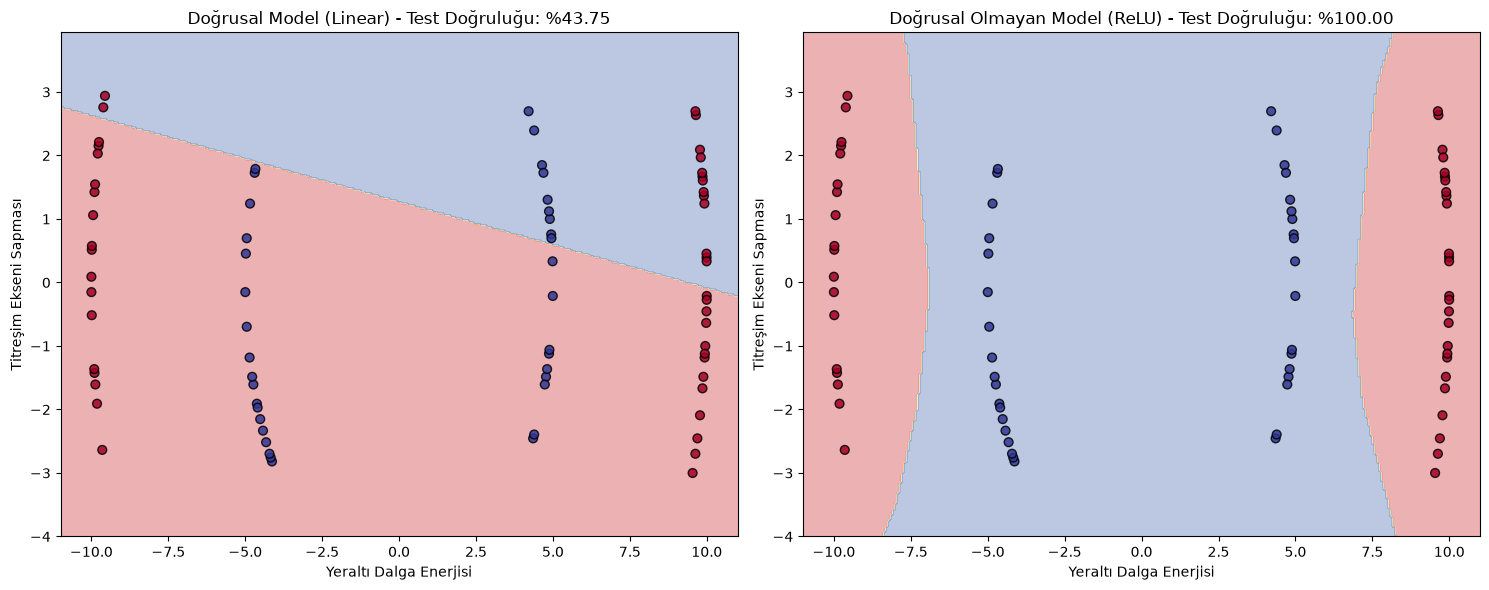

In [14]:
def plot_decision_boundary(model: nn.Module, X: torch.Tensor, y: torch.Tensor, title: str):
    """Modelin 2D uzaydaki karar sınırını renklendirerek çizer."""
    # Çizim sınırlarını belirle
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    # Izgara (Grid) oluştur
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    
    # Modelden tahmin al
    model.eval()
    with torch.inference_mode():
        preds = torch.round(torch.sigmoid(model(grid))).reshape(xx.shape).numpy()
        
    # Karar sınırını ve veri noktalarını çiz
    plt.contourf(xx, yy, preds, cmap=plt.cm.RdYlBu, alpha=0.35)
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap=plt.cm.RdYlBu, s=40, edgecolors="k", alpha=0.85)
    plt.title(title, fontsize=12)
    plt.xlabel("Yeraltı Dalga Enerjisi")
    plt.ylabel("Titreşim Ekseni Sapması")

# Yan yana karşılaştırma grafiği
plt.figure(figsize=(15, 6))

# Sol: Doğrusal Model
plt.subplot(1, 2, 1)
plot_decision_boundary(model_linear, X_test, y_test, "Doğrusal Model (Linear) - Test Doğruluğu: %43.75")

# Sağ: Doğrusal Olmayan Model
plt.subplot(1, 2, 2)
plot_decision_boundary(model_relu, X_test, y_test, "Doğrusal Olmayan Model (ReLU) - Test Doğruluğu: %100.00")

plt.tight_layout()
plt.show()

## 📝 Ödev Çıkarımları ve Karşılaştırma Tablosu

| Kriter / Özellik | Doğrusal Model (Linear) | Doğrusal Olmayan Model (ReLU) |
| :--- | :--- | :--- |
| **Aktivasyon Fonksiyonu** | Yok (None) | `nn.ReLU()` |
| **Katman Mimarisi** | `Linear(2,5) -> Linear(5,1)` | `Linear(2,16) -> ReLU -> Linear(16,16) -> ReLU -> Linear(16,1)` |
| **Karar Sınırı Şekli** | Dümdüz bir çizgi (Doğru) | Veriyi çevreleyen dairesel/kıvrımlı eğri |
| **Test Kaybı (Test Loss)** | `0.7140` (Yüksek) | `0.0004` (Sıfıra yakın mükemmel) |
| **Test Doğruluğu (Test Acc)**| **%43.75** (Yazı turadan kötü) | **%100.00** (Kusursuz başarı) |
| **Sonuç & Yorum** | Doğrusal olmayan veriyi öğrenemez | Derin öğrenmenin uzayı bükme gücünü kanıtlar |

---
*Tebrikler! Atıl Samancıoğlu Derin Öğrenme Modül 08 Sismik Aktivite Ödevi başarıyla tamamlanmıştır.*